# 06 · Model 2: does this head wear a helmet?

Same idea as Model 1: the frozen ResNet50 turns a head crop into a vector of 2,048 numbers, and one new dense layer makes the decision.

## Output A (helmet yes or no), step by step
| Step | Computation |
|---|---|
| Dropout 0.3 | Only during training: each of the 2,048 numbers is set to 0 with probability 0.3. This keeps the layer from relying on a few numbers. |
| Dense, 1 output | z = w · v + b, with 2,048 weights w and 1 bias b. |
| Sigmoid | P(helmet) = 1 / (1 + e^(−z)), a number between 0 and 1. |

- **Decision:** P(helmet) ≥ 0.5 means helmet. The 0.5 was fixed before looking at the test photos.
- **Class weights:** there are 4 times more heads without a helmet. Each class gets weight N / (2 · N_class), so both count the same in training.
- **Early stopping:** up to 60 epochs. Training stops when the loss on the *val* photos has not improved for 5 epochs, and keeps the weights of the best epoch. The *test* photos are used only once, at the end.

At the end we join Model 1 (color) and Model 2 (helmet) into one file with two outputs, because both read the same ResNet50 vector.

Inputs: `data/features/` (notebook 05), `models/helmet_color_model.keras` (notebook 04).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import confusion_matrix, roc_auc_score, balanced_accuracy_score
from PIL import Image, ImageOps

keras.utils.set_random_seed(0)
REPO = Path.cwd().parent
SHWD = REPO / "data/VOC2028"
FEATURES, OUTPUTS, MODELS = REPO / "data/features", REPO / "outputs", REPO / "models"
COLORS = ["green", "orange", "red", "transparent", "yellow"]

F = np.load(FEATURES / "shwd_head_vectors.npy").astype("float32")
heads = pd.read_csv(FEATURES / "shwd_heads.csv")
y = heads.y.to_numpy()
part = {p: (heads.split == p).to_numpy() for p in ["train", "val", "test"]}
pd.crosstab(heads.split, heads.label)

label,hat,person
split,,
test,1283,5433
train,4452,19627
val,562,2036


## 1. Train output A

training crops: no helmet 19627 | helmet 4452 | class weights {0: np.float64(0.613), 1: np.float64(2.704)}


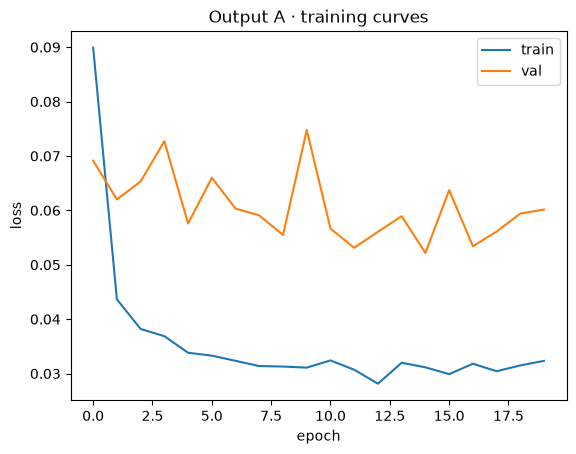

In [2]:
helmet_head = keras.Sequential([keras.Input((2048,)), layers.Dropout(0.3),
                                layers.Dense(1, activation="sigmoid", kernel_regularizer=keras.regularizers.l2(1e-3))],
                               name="helmet_head")
helmet_head.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])

n = np.bincount(y[part["train"]])
weight = {c: part["train"].sum() / (2 * n[c]) for c in (0, 1)}
print("training crops: no helmet", n[0], "| helmet", n[1], "| class weights", {k: round(v, 3) for k, v in weight.items()})

hist = helmet_head.fit(F[part["train"]], y[part["train"]], validation_data=(F[part["val"]], y[part["val"]]),
                       epochs=60, batch_size=64, class_weight=weight, verbose=0,
                       callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Output A · training curves")
plt.savefig(OUTPUTS / "06_training_curves.png", dpi=120); plt.show()

## 2. Test (used only once)

- **Sensitivity "no helmet"** = heads without a helmet found / all heads without a helmet. This is the most important number: a worker without a helmet that the system marks as protected is the dangerous error.
- **Specificity** = heads with a helmet recognized / all heads with a helmet.
- **Balanced accuracy** = the mean of the two. It is not inflated by the larger class.
- **ROC AUC**: the probability that a head with a helmet gets a higher P(helmet) than a head without one. It does not depend on the 0.5 threshold.

In [3]:
p = helmet_head.predict(F[part["test"]], verbose=0).ravel()
yt, pred = y[part["test"]], (p >= 0.5).astype(int)
(tn, fp), (fn, tp) = confusion_matrix(yt, pred)           # positive class = helmet
pd.Series({"test heads": len(yt),
           "sensitivity no helmet": tn / (tn + fp),
           "specificity (helmet recognized)": tp / (tp + fn),
           "accuracy": (pred == yt).mean(),
           "balanced accuracy": balanced_accuracy_score(yt, pred),
           "ROC AUC": roc_auc_score(yt, p)}).round(3)

test heads                         6716.000
sensitivity no helmet                 0.987
specificity (helmet recognized)       0.991
accuracy                              0.987
balanced accuracy                     0.989
ROC AUC                               0.999
dtype: float64

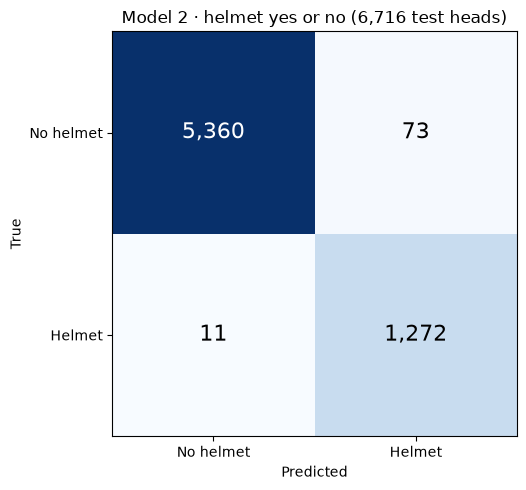

In [4]:
cm = confusion_matrix(yt, pred)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=16, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["No helmet", "Helmet"]); ax.set_yticks([0, 1], ["No helmet", "Helmet"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Model 2 · helmet yes or no ({len(yt):,} test heads)")
plt.tight_layout(); plt.savefig(OUTPUTS / "06_confusion_matrix_model2.png", dpi=150); plt.show()

### Wrong predictions on the test photos

Each image is the crop the model saw. Title: photo id, P(helmet) and head size in the original photo. We show the 16 most confident errors of each kind. Many heads "without a helmet" that the model marked as helmet wear a cap, a hat or a hood.

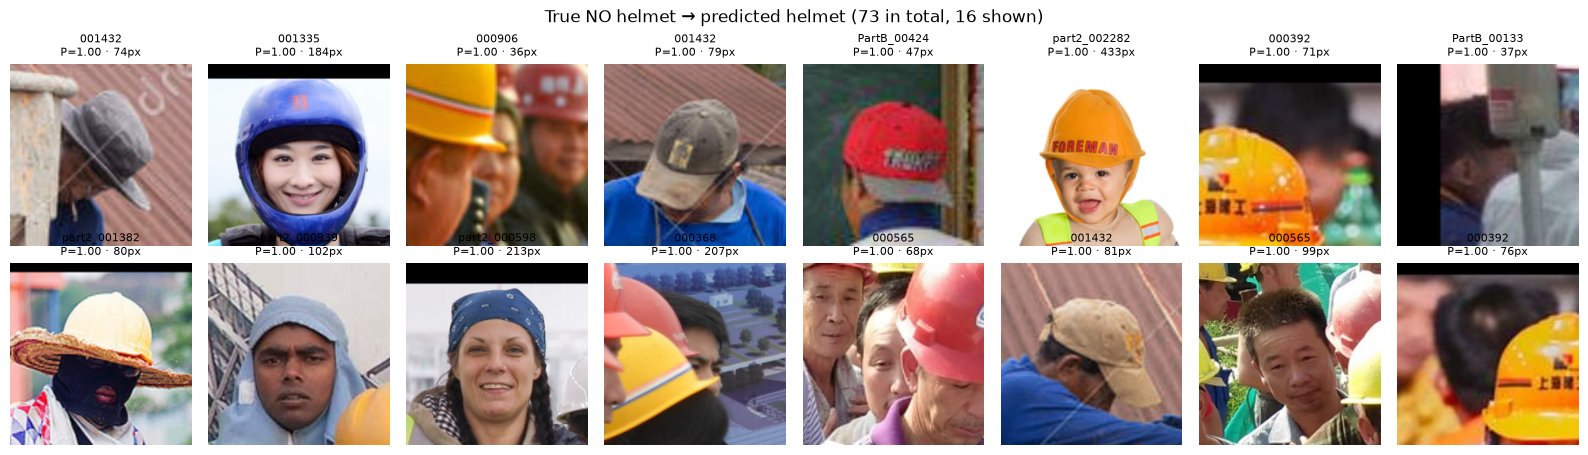

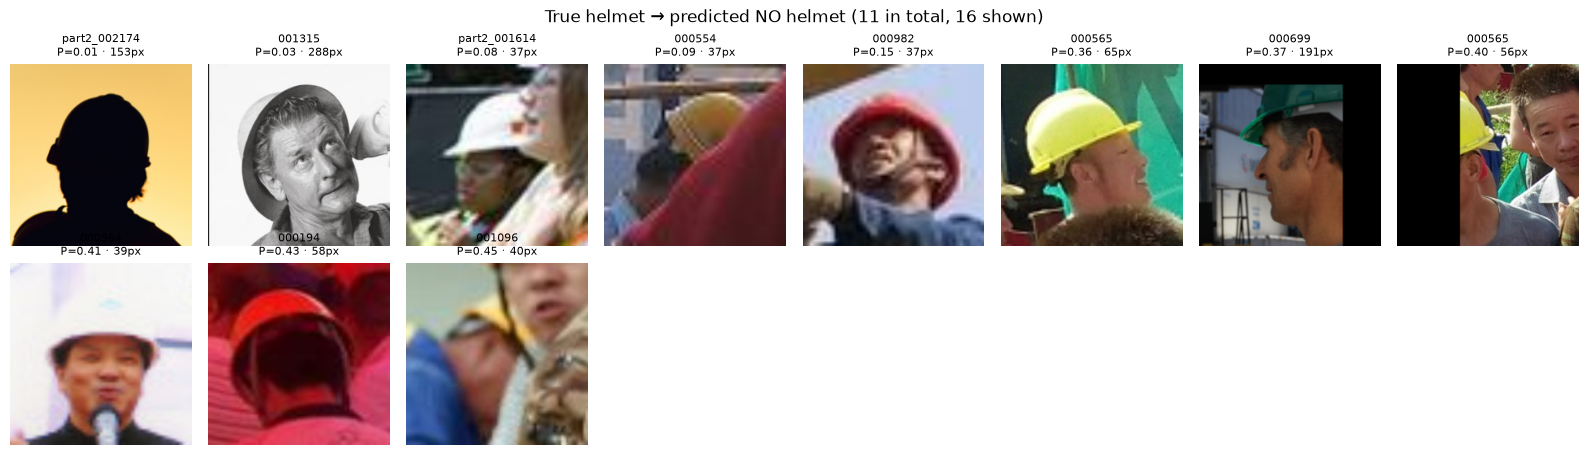

In [5]:
def head_crop(r):
    img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{r.id}.jpg")).convert("RGB")
    cx, cy, L = (r.x1 + r.x2) / 2, (r.y1 + r.y2) / 2, 1.3 * max(r.x2 - r.x1, r.y2 - r.y1)
    return img.crop((cx - L / 2, cy - L / 2, cx + L / 2, cy + L / 2)).resize((224, 224), Image.BILINEAR)

errors = heads[part["test"]].assign(p_helmet=p, pred=pred)
errors = errors[errors.pred != errors.y]
errors.to_csv(OUTPUTS / "06_test_errors.csv", index=False)

for true, title, ascending in [(0, "True NO helmet → predicted helmet", False), (1, "True helmet → predicted NO helmet", True)]:
    e = errors[errors.y == true].sort_values("p_helmet", ascending=ascending)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), e.head(16).iterrows()):
        ax.imshow(head_crop(r)); ax.set_title(f"{r.id}\nP={r.p_helmet:.2f} · {r.min_side}px", fontsize=8)
    fig.suptitle(f"{title} ({len(e)} in total, 16 shown)")
    plt.tight_layout(); plt.savefig(OUTPUTS / f"06_errors_true_{'helmet' if true else 'no_helmet'}.png", dpi=110); plt.show()

In [6]:
# Does the result depend on the head size in the original photo?
t = heads[part["test"]].assign(correct=pred == yt)
t["size"] = pd.cut(t.min_side, [32, 64, 128, 10_000], right=False, labels=["32–63 px", "64–127 px", "≥128 px"])
t.pivot_table(index="size", columns="label", values="correct", aggfunc=["size", "mean"], observed=True).round(3)

size          mean       
label      hat person    hat person
size                               
32–63 px   393   3505  0.982  0.991
64–127 px  392   1274  0.997  0.977
≥128 px    498    654  0.994  0.979

## 3. Join both outputs in one model

We load the color model from notebook 04 and reuse its layers: preprocessing, ResNet50 and the color layer. Both outputs read **the same vector**, so ResNet50 runs only once per head.

```
head 224×224×3 → resnet_preprocess → resnet50 → vector (2,048) ─┬─ helmet_head → P(helmet)
                                                                └─ color_head  → P(green … yellow)
```
Output A was trained on vectors from the **same** ResNet50 (same weights, same preprocessing), so it can be attached directly. The check below confirms it.

In [7]:
color = keras.models.load_model(MODELS / "helmet_color_model.keras")
inp = keras.Input((224, 224, 3), name="head_224")
v = color.get_layer("resnet50")(color.get_layer("resnet_preprocess")(inp))
model = keras.Model(inp, {"helmet": helmet_head(v), "color": color.get_layer("color_head")(v)}, name="helmet_and_color")
model.summary()

# Check: the joined model gives the same answers as each part alone
from keras.applications.resnet50 import preprocess_input
X_check = np.random.default_rng(0).integers(0, 256, (4, 224, 224, 3)).astype("float32")
out = model.predict(X_check, verbose=0)
v_ref = color.get_layer("resnet50").predict(preprocess_input(X_check.copy()), verbose=0)
assert np.allclose(out["helmet"], helmet_head.predict(v_ref, verbose=0), atol=1e-4)
assert np.allclose(out["color"], color.predict(X_check, verbose=0), atol=1e-4)

model.save(MODELS / "helmet_and_color.keras")

Model: "helmet_and_color"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ head_224            │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet_preprocess   │ (None, 224, 224,  │         12 │ head_224[0][0]    │
│ (Conv2D)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 2048)      │ 23,587,712 │ resnet_preproces… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ color_head          │ (None, 5)         │     10,245 │ resnet50[1][0]    │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ helmet_head         │ (None, 1)         │      2,049 │ resnet50[1][0]    │
│ (Sequential)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,600,018 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,724 (89.98 MB)

## 4. Control: what does output A say about our 174 helmet photos?

These helmets are not worn by anyone, so this is not the task output A was trained for. It is only a control: most should come out as "helmet", and the color output should still be right.

In [8]:
meta = pd.read_csv(REPO / "data/helmets/helmets_metadata.csv")
ours = meta[meta.dataset_folder == "Cartella DATASET Algoritmo convegno"]
Xo = np.stack([np.asarray(ImageOps.exif_transpose(Image.open(REPO / "data/helmets" / r)).convert("RGB").resize((224, 224), Image.BILINEAR))
               for r in ours.relative_path]).astype("float32")
oo = model.predict(Xo, verbose=0)
res = pd.DataFrame({"true color": ours.helmet_color.to_numpy(), "P(helmet)": oo["helmet"].ravel(),
                    "predicted color": np.array(COLORS)[oo["color"].argmax(1)]})
res["color_ok"] = res["true color"] == res["predicted color"]
res.groupby("true color").agg(n=("P(helmet)", "size"), mean_P_helmet=("P(helmet)", "mean"),
                              pct_helmet=("P(helmet)", lambda s: (s >= 0.5).mean()),
                              color_ok=("color_ok", "mean")).round(3)

,n,mean_P_helmet,pct_helmet,color_ok
true color,,,,
green,28,0.913,0.929,1.0
orange,31,1.000,1.000,1.0
red,33,0.847,0.909,1.0
transparent,30,0.908,0.967,1.0
yellow,52,1.000,1.000,1.0
